In [110]:
import numpy as np
import pandas as pd
import os
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.font_manager as fm
import seaborn as sns
from helper import read_json_to_dict
from fonts import get_project_font

In [111]:
FONT_GOTHIC_PATH, FONT_DREAM_PATH = get_project_font()

matplotlib.use("agg")
# DBGOTHIC = fm.FontProperties(fname=FONT_GOTHIC_PATH).get_name()
DBGOTHIC = fm.FontProperties(fname=FONT_GOTHIC_PATH)
DBDREAM = fm.FontProperties(fname=FONT_DREAM_PATH)
fm.fontManager.addfont(FONT_GOTHIC_PATH)
fm.fontManager.addfont(FONT_DREAM_PATH)

# plt.rc('font', family=DBGOTHIC)
plt.rcParams['font.family'] = DBGOTHIC.get_name()
plt.rcParams['axes.unicode_minus'] = False

In [112]:
%matplotlib inline

In [113]:
project_dir = r'C:\Users\10007166\insightmaker_project\Temp'
data_path = os.path.join(project_dir, 'data.pkl')
column_info_path = os.path.join(project_dir, 'column_info.json')
df = pd.read_pickle(data_path)
col_info = read_json_to_dict(column_info_path)

In [124]:
import random

In [138]:
dt_col_info = random.choice([col for col in col_info if col['ColumnChar']=='DateTime'])
cont_col_info = random.choice([col for col in col_info if col['ColumnChar']=='Continuous'])
disc_col_info = random.choice([col for col in col_info if col['ColumnChar']=='Discrete'])
cat_col_info = random.choice([col for col in col_info if col['ColumnChar']=='Nominal'])
cat_group_col_info = random.choice([col for col in col_info if (col['ColumnChar']=='Nominal') and (col['Column']!=cat_col_info['Column'])])

In [139]:
print(f"DateTime 컬럼: {dt_col_info['Column']}")
print(f"Continuous 컬럼: {cont_col_info['Column']}")
print(f"Discrete 컬럼: {disc_col_info['Column']}")
print(f"Categorical 컬럼: {cat_col_info['Column']}")
print(f"Categorical(그룹) 컬럼: {cat_group_col_info['Column']}")

DateTime 컬럼: column13
Continuous 컬럼: column9
Discrete 컬럼: column12
Categorical 컬럼: column3
Categorical(그룹) 컬럼: column7


In [141]:
def add_datetime_bins(df, dt_col, dt_bins, suffix, max_bin_size=30):
    bins_unique = dt_bins.unique()
    if len(bins_unique)>1 and len(bins_unique)<max_bin_size:
        df[f"{dt_col}_{suffix}"] = dt_bins
    return df     

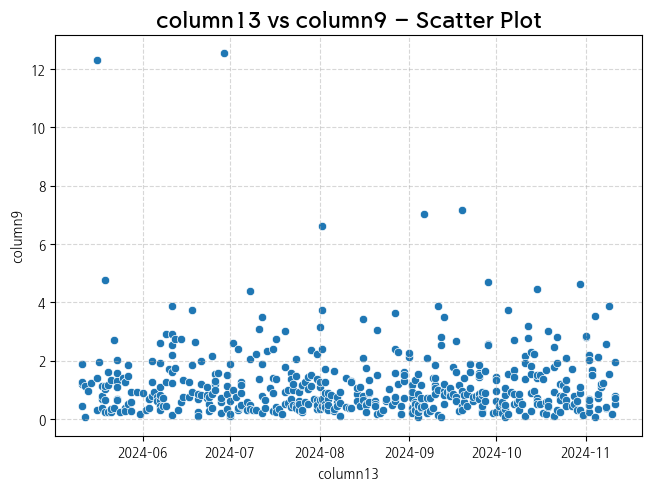

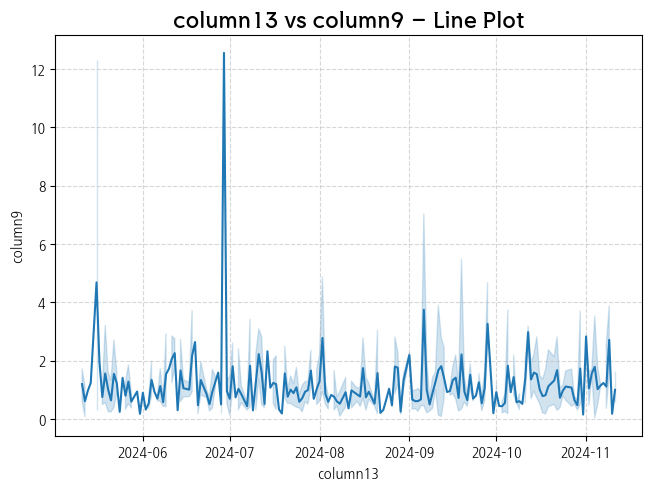

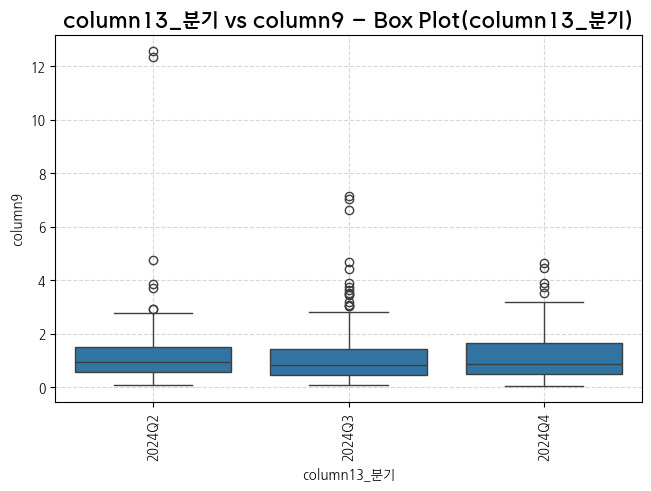

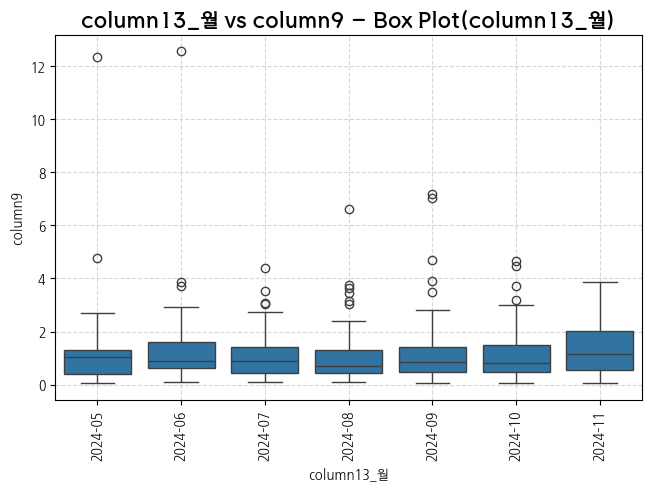

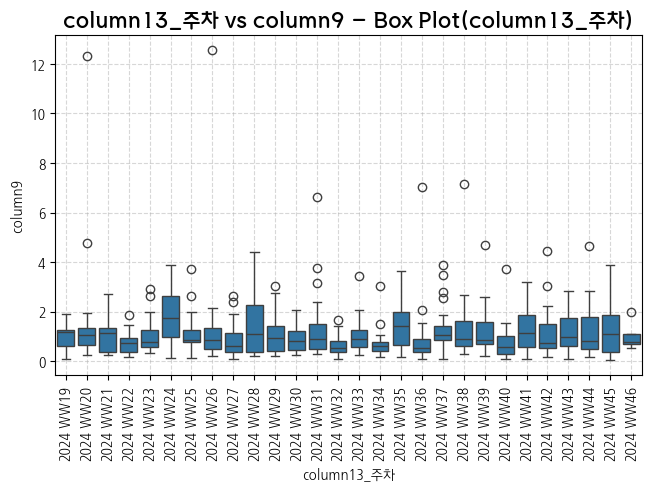

In [142]:
# case1: DateTime vs Numeric
dt_col = dt_col_info['Column']
num_col = cont_col_info['Column']
is_x_axis = True # DateTime 기준

df_sort = df.sort_values(dt_col).reset_index(drop=True)
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.year, 'Year')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.to_period('Q'), '분기')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.to_period('M'), '월')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%Y WW%W'), '주차')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%Y-%m-%d'), '날짜')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%y/%m/%d %H'), '시간')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%y/%m/%d %H:%M'), '분')

dt_bin_cols = [col for col in df_sort.columns if len(col)>len(dt_col) and col.startswith(dt_col)]

x_col, y_col = None, None
if is_x_axis:
    x_col, y_col = dt_col, num_col
else:
    x_col, y_col = num_col, dt_col

# 1. 산점도
title = f"{x_col} vs {y_col} - Scatter Plot"
fig, ax = plt.subplots(layout='constrained')
sns.scatterplot(x=x_col, y=y_col, data=df_sort, ax=ax)
ax.set_title(title, fontdict=dict(fontsize=15, fontweight='bold', fontproperties=DBDREAM))
ax.grid(True, linestyle='--', alpha=.5)
plt.show()

# 2. Line Plot
title = f"{x_col} vs {y_col} - Line Plot"
fig, ax = plt.subplots(layout='constrained')
sns.lineplot(x=x_col, y=y_col, data=df, ax=ax)
ax.set_title(title, fontdict=dict(fontsize=15, fontweight='bold', fontproperties=DBDREAM))
ax.grid(True, linestyle='--', alpha=.5)
plt.show()

# 3. Box Plot
for dt_bin in dt_bin_cols:
    if is_x_axis:
        x_col, y_col = dt_bin, num_col
    else:
        x_col, y_col = num_col, dt_bin
    title = f"{x_col} vs {y_col} - Box Plot({dt_bin})"
    fig, ax = plt.subplots(layout='constrained')
    sns.boxplot(x=x_col, y=y_col, data=df_sort, ax=ax)
    ax.set_title(title, fontdict=dict(fontsize=15, fontweight='bold', fontproperties=DBDREAM))
    ax.grid(True, linestyle='--', alpha=.5)
    ax.set_xticks(ax.get_xticks(), ax.get_xticklabels(), rotation=90, ha='center')
    plt.show()

In [2]:
is_true = True
print(not is_true)

False


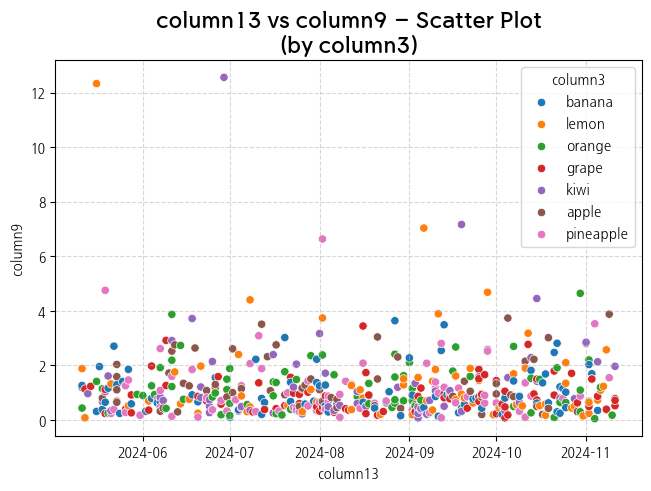

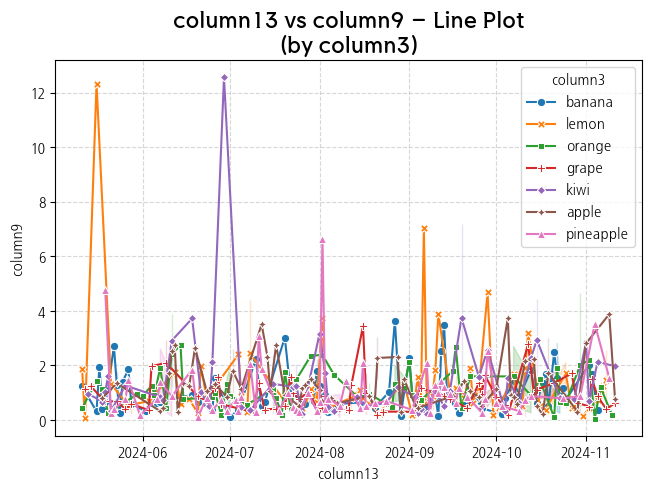

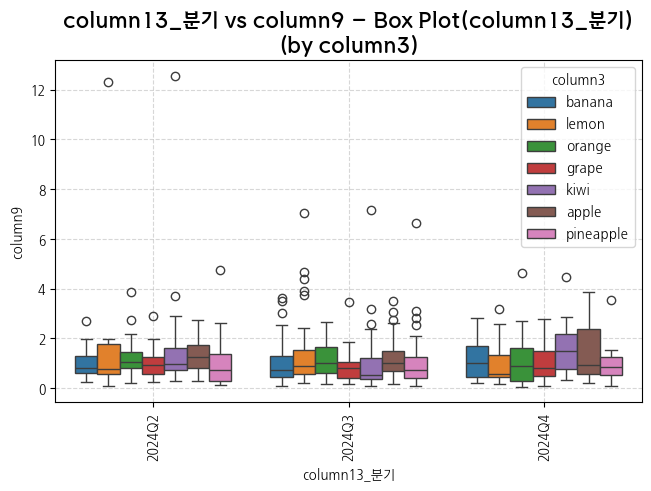

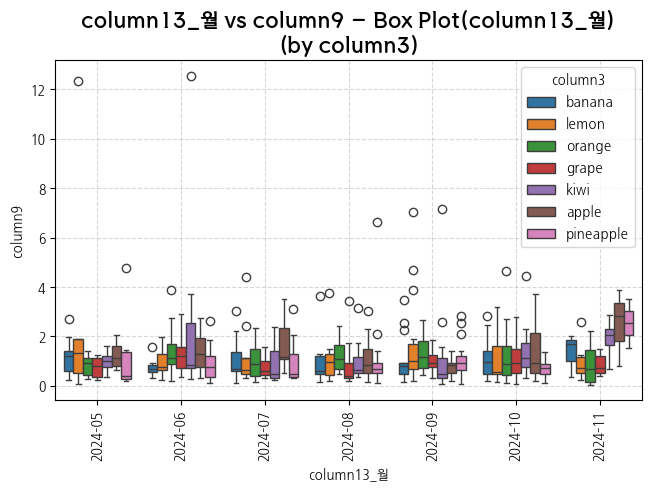

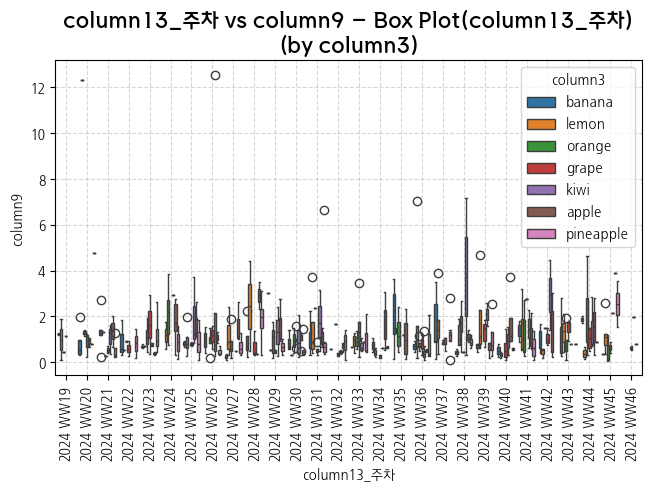

In [143]:
# case2: DateTime vs Numeric by Categorical
dt_col = dt_col_info['Column']
num_col = cont_col_info['Column']
g_col = cat_col_info['Column']
is_x_axis = True # DateTime 기준

df_sort = df.sort_values(dt_col).reset_index(drop=True)
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.year, 'Year')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.to_period('Q'), '분기')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.to_period('M'), '월')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%Y WW%W'), '주차')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%Y-%m-%d'), '날짜')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%y/%m/%d %H'), '시간')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%y/%m/%d %H:%M'), '분')

dt_bin_cols = [col for col in df_sort.columns if len(col)>len(dt_col) and col.startswith(dt_col)]

x_col, y_col = None, None
if is_x_axis:
    x_col, y_col = dt_col, num_col
else:
    x_col, y_col = num_col, dt_col

# 1. 산점도
title = f"{x_col} vs {y_col} - Scatter Plot\n(by {g_col})"
fig, ax = plt.subplots(layout='constrained')
sns.scatterplot(x=x_col, y=y_col, hue=g_col, data=df_sort, ax=ax)
ax.set_title(title, fontdict=dict(fontsize=15, fontweight='bold', fontproperties=DBDREAM))
ax.grid(True, linestyle='--', alpha=.5)
plt.show()

# 2. Line Plot
title = f"{x_col} vs {y_col} - Line Plot\n(by {g_col})"
fig, ax = plt.subplots(layout='constrained')
sns.lineplot(x=x_col, y=y_col, hue=g_col, style=g_col, data=df_sort, ax=ax, markers=True, dashes=False)
ax.set_title(title, fontdict=dict(fontsize=15, fontweight='bold', fontproperties=DBDREAM))
ax.grid(True, linestyle='--', alpha=.5)
plt.show()

# 3. Box Plot
for dt_bin in dt_bin_cols:
    if is_x_axis:
        x_col, y_col = dt_bin, num_col
    else:
        x_col, y_col = num_col, dt_bin
    title = f"{x_col} vs {y_col} - Box Plot({dt_bin})\n(by {g_col})"
    fig, ax = plt.subplots(layout='constrained')
    sns.boxplot(x=x_col, y=y_col, hue=g_col, data=df_sort, ax=ax)
    ax.set_title(title, fontdict=dict(fontsize=15, fontweight='bold', fontproperties=DBDREAM))
    ax.grid(True, linestyle='--', alpha=.5)
    ax.set_xticks(ax.get_xticks(), ax.get_xticklabels(), rotation=90, ha='center')
    plt.show()

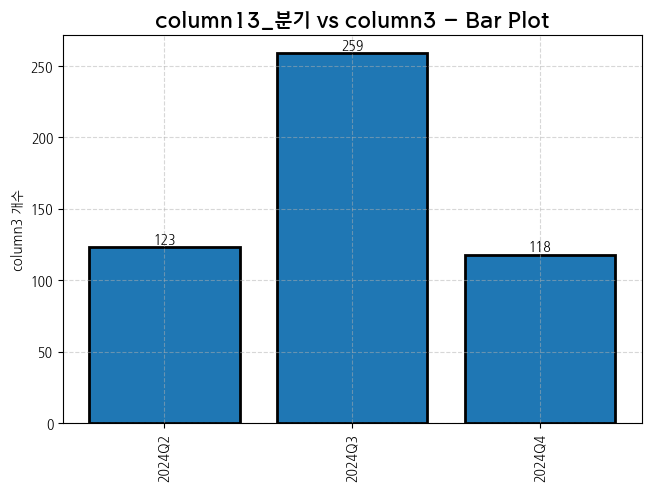

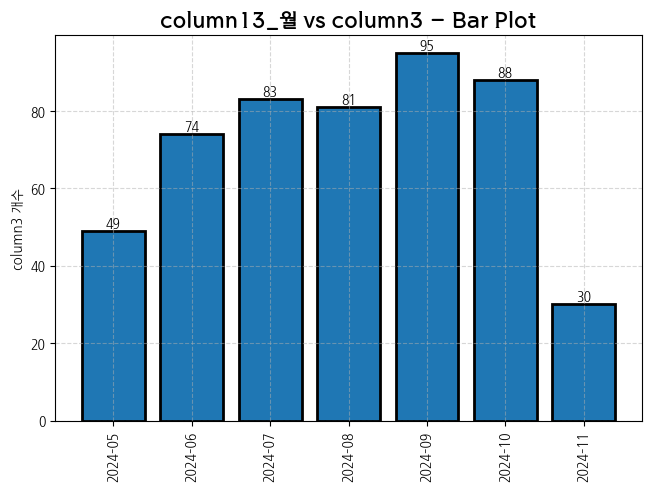

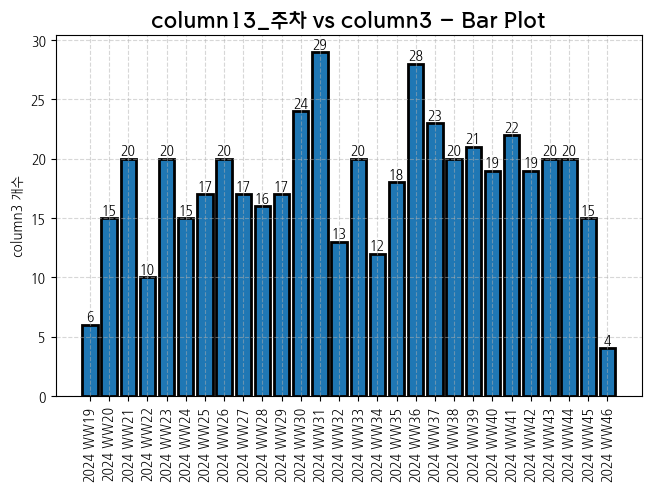

In [144]:
# case3: DateTime vs Categorical
dt_col = dt_col_info['Column']
cat_col = cat_col_info['Column']
is_x_axis = True # DateTime 기준

df_sort = df.sort_values(dt_col).reset_index(drop=True)
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.year, 'Year')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.to_period('Q'), '분기')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.to_period('M'), '월')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%Y WW%W'), '주차')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%Y-%m-%d'), '날짜')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%y/%m/%d %H'), '시간')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%y/%m/%d %H:%M'), '분')

dt_bin_cols = [col for col in df_sort.columns if len(col)>len(dt_col) and col.startswith(dt_col)]

for dt_bin in dt_bin_cols:
    x_col, y_col = None, None
    if is_x_axis:
        x_col, y_col = dt_bin, cat_col
    else:
        x_col, y_col = cat_col, dt_bin
    df_count = df_sort.pivot_table(
        index=dt_bin,
        values=cat_col,
        aggfunc='count'
    ).reset_index()
    df_count[dt_bin] = df_count[dt_bin].astype(str)
    
    # 1. Bar Chart
    title = f"{x_col} vs {y_col} - Bar Plot"
    fig, ax = plt.subplots(layout='constrained')    
    bar_chart = ax.bar(df_count[x_col], df_count[y_col], linewidth=2, edgecolor='black')
    ax.bar_label(bar_chart, fmt=lambda x: f"{x:,.0f}")
    ax.set_xticks(ax.get_xticks(), ax.get_xticklabels(), rotation=90, ha='center')
    ax.set_ylabel(f'{y_col} 개수', fontdict=dict(fontweight='bold'))
    ax.set_title(title, fontdict=dict(fontsize=15, fontweight='bold', fontproperties=DBDREAM))
    ax.grid(True, linestyle='--', alpha=.5)
    plt.show()

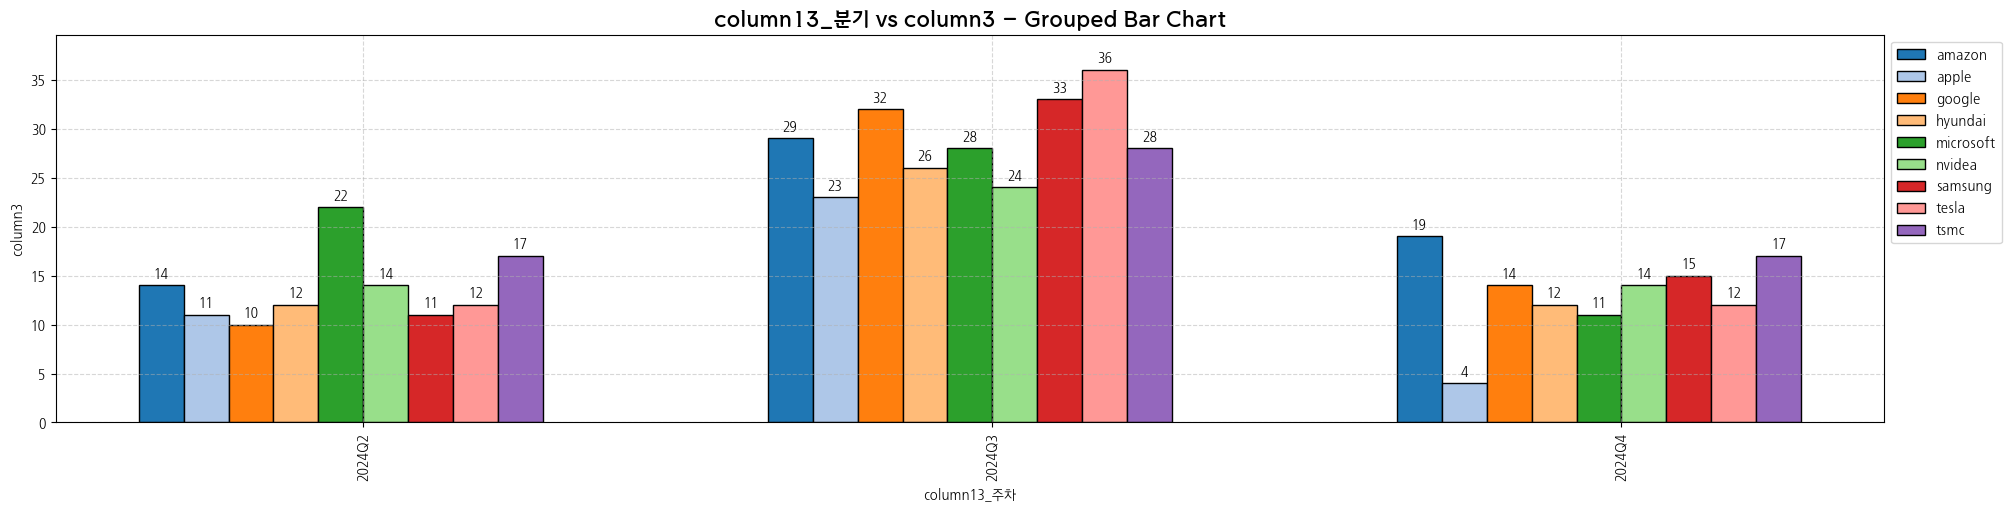

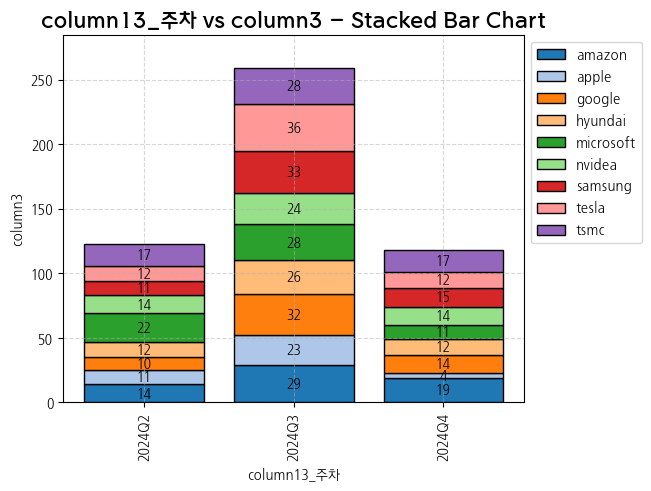

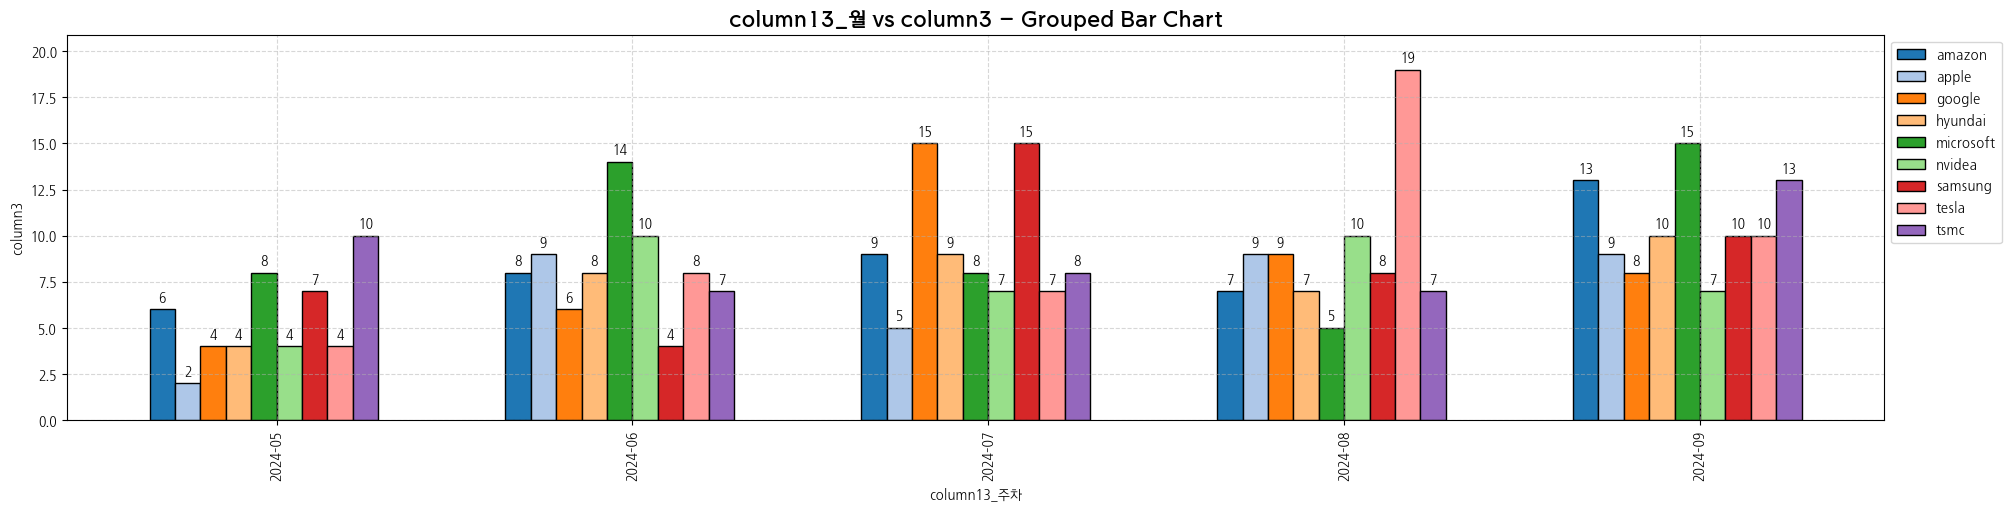

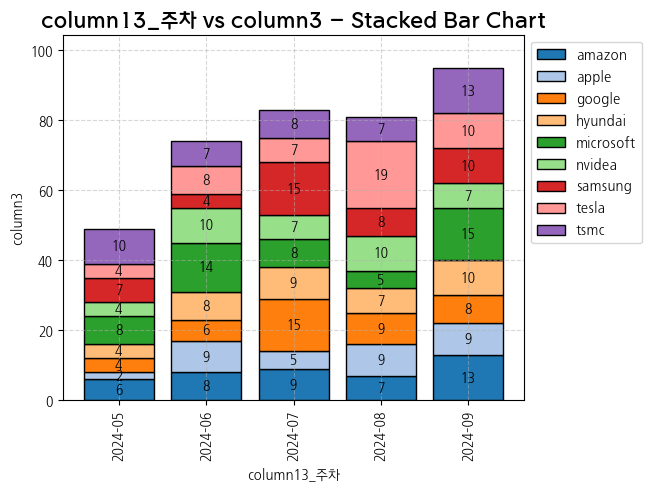

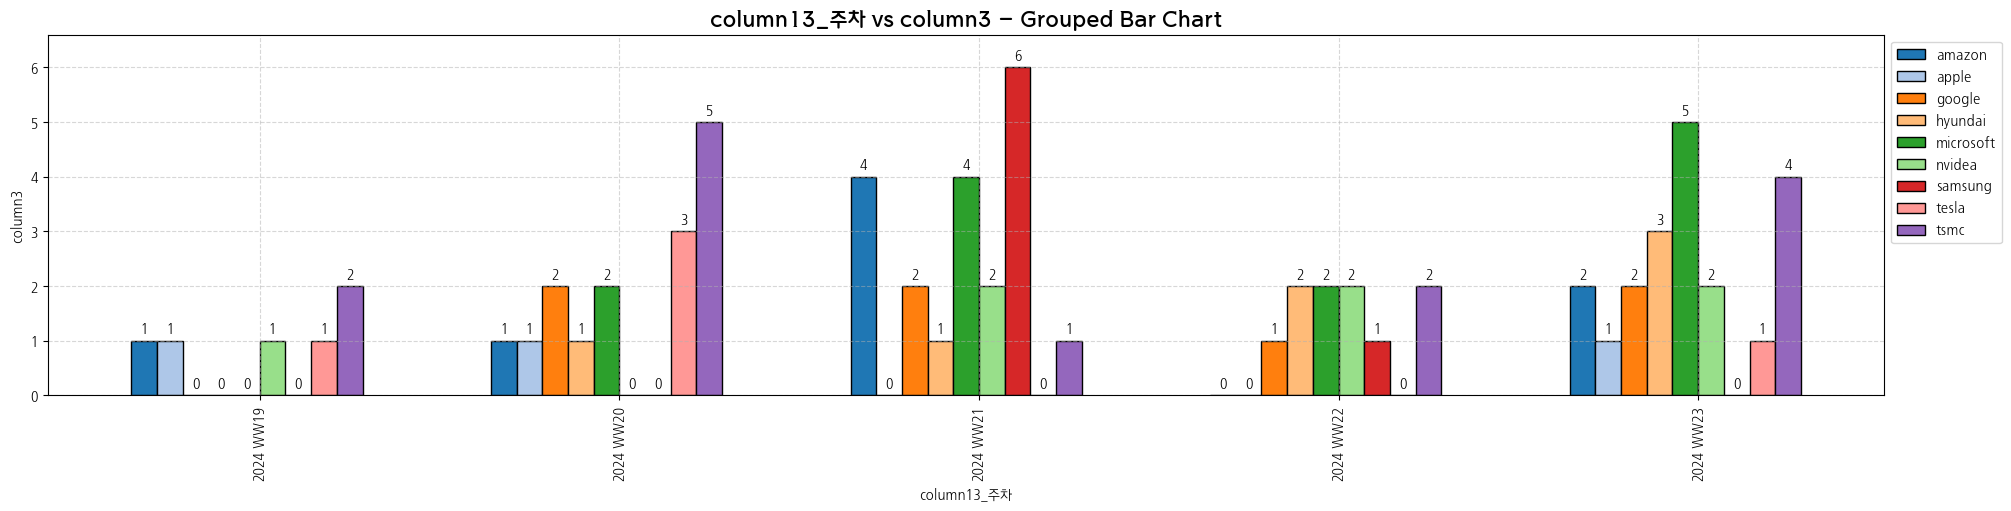

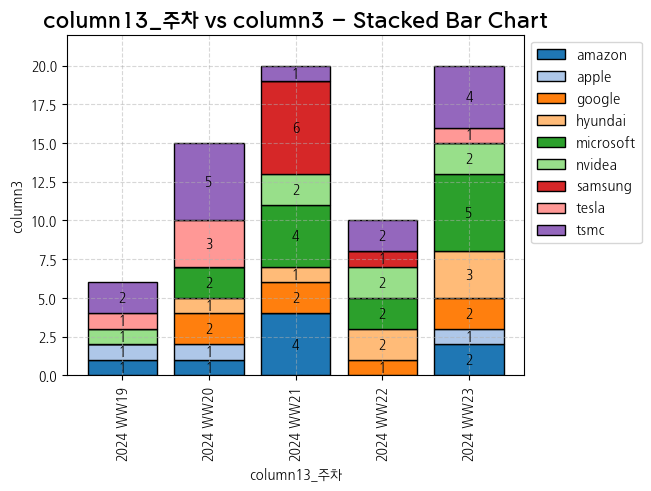

In [252]:
# case4: DateTime vs Categorical by Categorical
dt_col = dt_col_info['Column']
cat_col = cat_col_info['Column']
g_col = cat_group_col_info['Column']
is_x_axis = True # DateTime 기준

df_sort = df.sort_values(dt_col).reset_index(drop=True)
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.year, 'Year')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.to_period('Q'), '분기')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.to_period('M'), '월')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%Y WW%W'), '주차')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%Y-%m-%d'), '날짜')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%y/%m/%d %H'), '시간')
df_sort = add_datetime_bins(df_sort, dt_col, df_sort[dt_col].dt.strftime('%y/%m/%d %H:%M'), '분')

dt_bin_cols = [col for col in df_sort.columns if len(col)>len(dt_col) and col.startswith(dt_col)]

for dt_bin in dt_bin_cols:
    # 1. Grouped Bar Chart    
    df_group = df_sort.pivot_table(
            index=dt_bin,
            columns=g_col,
            values=cat_col,
            aggfunc='count',
            fill_value=0
        ).reset_index()

    x_values = df_group[dt_bin].to_list()
    y_values = {col:tuple(df_group[col]) for col in df_group.columns if col != dt_bin}

    width = 0.2
    diff = 1
    x_indices = []
    for i in range(len(x_values)):
        if i==0:
            x_indices.append(diff)
        else:
            before = x_indices[i-1]
            x_indices.append(before + diff + width*len(y_values))
    x_indices = np.array(x_indices)

    title = f'{dt_bin} vs {y_col} - Grouped Bar Chart'
    fig, ax = plt.subplots(layout='constrained', figsize=(20,5))
    cmap = plt.get_cmap('tab20')

    for i, (attr, measurment) in enumerate(y_values.items()):
        offset = i*width
        rects = ax.bar(x_indices+offset, measurment, width, label=attr, color=cmap(i),
                    linewidth=1, edgecolor='black')
        ax.bar_label(rects, padding=3, fmt='{:,.0f}')

    ax.set_ylim(0, max([max(values) for values in y_values.values()])*1.1)
    ax.set_ylabel(y_col, fontdict=dict(fontweight='bold'))
    # ax.yaxis.set_major_formatter(FuncFormatter(formatter_kmb))
    ax.set_xticks(x_indices+width*len(y_values)/2, x_values, rotation=90, ha='center')
    ax.set_xlabel(x_col, fontdict=dict(fontweight='bold'))
    ax.set_title(title,
                fontdict=dict(fontsize=15, fontweight='bold', fontproperties=DBDREAM))
    ax.grid(True, linestyle='--', alpha=.5)
    ax.legend(loc='upper left', ncols=1, bbox_to_anchor=(1,1))
    plt.show()
    
    # 2. Stacked Bar Chart   
    title = f'{x_col} vs {y_col} - Stacked Bar Chart'
    x_indices = np.arange(len(x_values))
    bottom = np.zeros(len(x_values))

    fig, ax = plt.subplots(layout='constrained')
    cmap = plt.get_cmap('tab20')

    for i, (attr, measurment) in enumerate(y_values.items()):
        rects = ax.bar(x_indices, measurment, label=attr, bottom=bottom, color=cmap(i),
                    linewidth=1, edgecolor='black')
        ax.bar_label(rects, label_type='center',
                    labels=[f'{value:,.0f}' if value>0 else '' for value in measurment])
        bottom += measurment

    ax.set_ylim(0, bottom.max()*1.1)
    # ax.yaxis.set_major_formatter(FuncFormatter(formatter_kmb))
    ax.set_ylabel(y_col, fontdict=dict(fontweight='bold'))
    ax.set_xticks(x_indices, x_values)
    ax.set_xlabel(x_col, fontdict=dict(fontweight='bold'))
    ax.set_xticks(ax.get_xticks(), ax.get_xticklabels(), rotation=90, ha='center')
    ax.set_title(title,
                fontdict=dict(fontsize=15, fontweight='bold', fontproperties=DBDREAM))
    ax.grid(True, linestyle='--', alpha=.5)
    ax.legend(loc='upper left', ncols=1, bbox_to_anchor=(1,1))
    plt.show()

In [ ]:
# Group by DateTime - DateTime 분리 필수 (12개 이하)
# 1. num vs num: 산점도 
# 2. num vs cat
# 3. cat vs cat